
# ChurnGuard AI — Predictive Customer Health Scoring & AI-Generated Renewal Briefs

**What this is:** a two-sided account health-scoring system for a B2B
SaaS company (2,800 accounts) that scores every account on BOTH churn
risk and expansion opportunity — not just "who's leaving," because a real
revenue team needs "who's leaving" (Customer Success) and "who's ready to
buy more" (Sales) as two different, differently-actioned lists — combined
into a 2×2 health quadrant, and paired with **AI-generated, evidence-
grounded renewal briefs** for the highest-priority upcoming renewals, the
kind of pre-call prep an account team would otherwise spend 20-30 minutes
assembling by hand.

**Why two models, not one:** a single blended "health score" would hide
the fact that a high-usage, high-risk account (see Section 5) needs a
completely different conversation than a high-usage, low-risk one — the
label "healthy" or "at risk" alone throws away exactly the nuance a human
account manager needs.

**On the LLM backend:** same cached/live design as the rest of this
portfolio — see `../shared/llm_client.py`. Every renewal brief below was
authored by reading the *actual* per-account diagnostic evidence computed
in this notebook (real utilization trend, real support-ticket signal,
real NPS), not invented — including briefs that explicitly push back on
the model's own quadrant label when the evidence is more nuanced than the
label suggests (see ACCT60347 in Section 6).


In [1]:

import sys, json
sys.path.insert(0, "../../shared")
sys.path.insert(0, "../pipeline")
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from health_scoring import prepare_features, train_model, assign_quadrant
from llm_client import get_client

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

conn = sqlite3.connect("../data/churnguard.db")
accounts = pd.read_sql_query("SELECT * FROM accounts", conn)
print(f"{len(accounts):,} accounts | churn rate {accounts.churned.mean():.1%} | "
      f"expansion-candidate rate {accounts.expanded.mean():.1%} | "
      f"total MRR ${accounts.mrr.sum():,.0f}")


2,800 accounts | churn rate 22.2% | expansion-candidate rate 13.3% | total MRR $3,944,116


## 1. Topline Health KPIs by Plan & Contract

In [2]:

kpis = pd.read_sql_query(open("../sql/01_health_kpis.sql").read(), conn)
kpis


,plan_tier,contract_type,total_accounts,churned_accounts,churn_rate_pct,expanded_accounts,expansion_rate_pct,mrr_churned,mrr_from_expansion_candidates
0,Starter,Monthly,566,283,50.0,56,9.9,35586.50,6936.29
1,Growth,Monthly,550,150,27.3,64,11.6,103684.52,48210.96
2,Starter,Annual,583,101,17.3,80,13.7,12314.17,9617.89
3,Enterprise,Monthly,267,31,11.6,45,16.9,201204.49,261684.84
4,Growth,Annual,566,46,8.1,87,15.4,30743.31,66670.46
5,Enterprise,Annual,268,11,4.1,41,15.3,53168.26,249822.37


## 2. Leakage-Free Feature Engineering (SQL window functions)

`sql/02_feature_engineering.sql` snapshots each account's features as of the month BEFORE its churn or expansion event (or its latest month, for accounts with neither outcome yet) — both labels are predicted ahead of time, not read off the event month itself.

In [3]:

snapshot = pd.read_sql_query(open("../sql/02_feature_engineering.sql").read(), conn)
print(snapshot.shape)
snapshot.head(3)


(2800, 17)


,account_id,plan_tier,contract_type,industry,region,seat_count,mrr,nps_score,churned,expanded,days_to_renewal,tenure_months_at_snapshot,utilization_pct,util_3mo_avg,util_trend_pct_3mo,tickets_trailing_3mo,negative_tickets_trailing_3mo
0,ACCT60000,Starter,Annual,Financial Services,North America,14,203.91,6.0,0,0,305,14,14.3,11.9,0.0,1,1
1,ACCT60001,Growth,Annual,Education,APAC,35,767.52,54.0,0,0,152,7,34.3,34.3,33.5,5,0
2,ACCT60002,Growth,Annual,Retail,EMEA,45,1072.12,NaN,1,0,1,16,62.2,58.5,3.7,1,0


## 3. Two Models: Churn Risk AND Expansion Opportunity

In [4]:

df_model, feature_cols = prepare_features(snapshot)
churn_clf, churn_auc = train_model(df_model, feature_cols, "churned")
expansion_clf, expansion_auc = train_model(df_model, feature_cols, "expanded")
print(f"Churn model AUC:     {churn_auc:.3f}")
print(f"Expansion model AUC: {expansion_auc:.3f}")

df_model["churn_risk_score"] = churn_clf.predict_proba(df_model[feature_cols])[:, 1]
df_model["expansion_score"] = expansion_clf.predict_proba(df_model[feature_cols])[:, 1]
df_model["account_id"] = snapshot["account_id"].values


Churn model AUC:     0.837
Expansion model AUC: 0.961


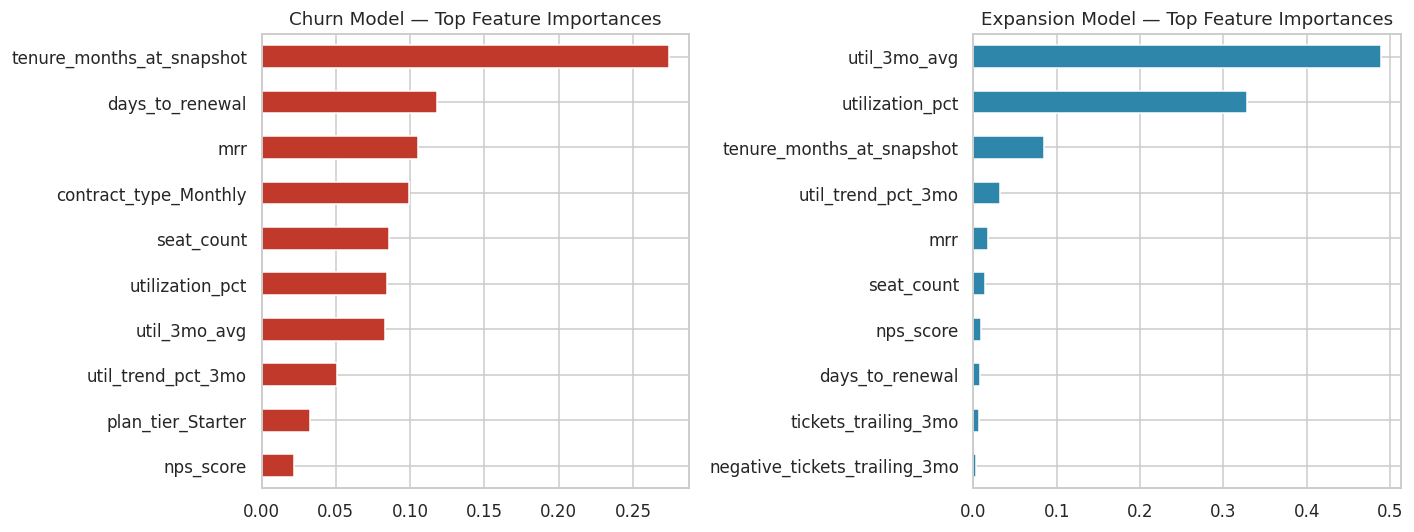

In [5]:

churn_importance = pd.Series(churn_clf.feature_importances_, index=feature_cols).sort_values(ascending=True).tail(10)
exp_importance = pd.Series(expansion_clf.feature_importances_, index=feature_cols).sort_values(ascending=True).tail(10)

fig, axes = plt.subplots(1, 2, figsize=(13,5))
churn_importance.plot(kind="barh", ax=axes[0], color="#C0392B")
axes[0].set_title("Churn Model — Top Feature Importances")
exp_importance.plot(kind="barh", ax=axes[1], color="#2E86AB")
axes[1].set_title("Expansion Model — Top Feature Importances")
plt.tight_layout()
plt.savefig("../dashboard/feature_importance.png", dpi=150)
plt.show()


**Reading this:** both models lean heavily on utilization signal (level
and trend), but in opposite directions — low/declining utilization drives
churn risk, high/sustained utilization drives expansion score — which is
exactly the mechanism the data was designed around, and validates that
the models learned something structurally sensible rather than
overfitting to noise.

## 4. The 2×2 Health Quadrant

In [6]:

df_model["quadrant"] = [assign_quadrant(r, e) for r, e in zip(df_model.churn_risk_score, df_model.expansion_score)]
merged = snapshot.merge(df_model[["account_id","churn_risk_score","expansion_score","quadrant"]], on="account_id")
active = merged[merged.churned == 0].copy()

quadrant_summary = active.groupby("quadrant").agg(
    accounts=("account_id","count"), total_mrr=("mrr","sum"), avg_churn_risk=("churn_risk_score","mean"),
    avg_expansion_score=("expansion_score","mean"),
).round(3).sort_values("accounts", ascending=False)
quadrant_summary


,accounts,total_mrr,avg_churn_risk,avg_expansion_score
quadrant,,,,
Stable — Maintain,983,1920776.99,0.205,0.058
At Risk — Save,540,423678.15,0.514,0.040
Growth Opportunity,465,1093123.53,0.170,0.715
Engaged but Unstable,190,69835.78,0.523,0.749


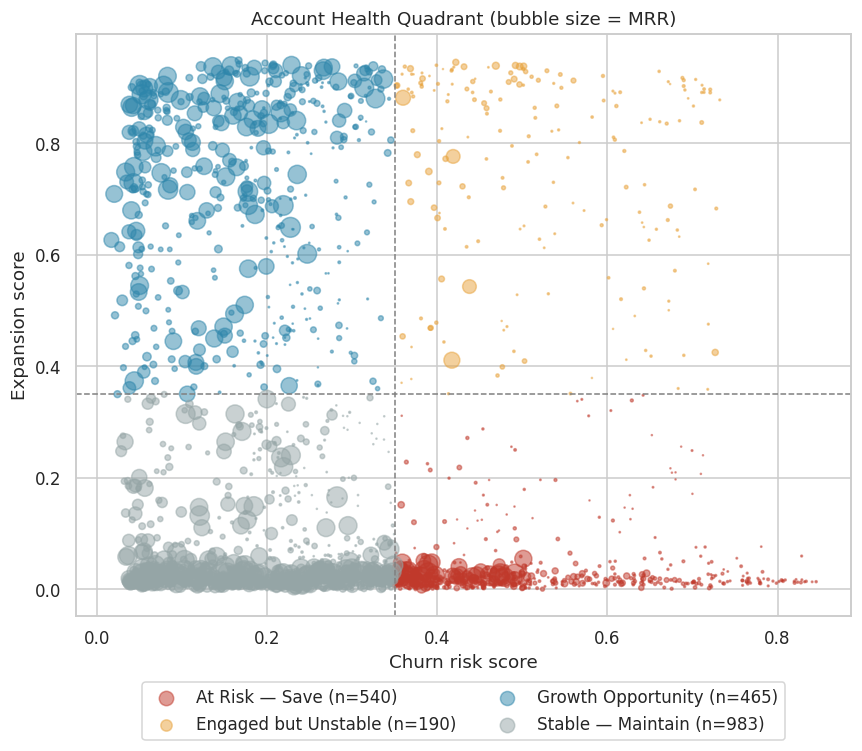

In [7]:

fig, ax = plt.subplots(figsize=(8,7))
colors = {"At Risk — Save": "#C0392B", "Growth Opportunity": "#2E86AB",
          "Engaged but Unstable": "#E8A33D", "Stable — Maintain": "#95A5A6"}
for q, sub in active.groupby("quadrant"):
    ax.scatter(sub.churn_risk_score, sub.expansion_score, s=sub.mrr/60, alpha=0.5,
               color=colors[q], label=f"{q} (n={len(sub)})")
ax.axvline(0.35, color="grey", linestyle="--", linewidth=1)
ax.axhline(0.35, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Churn risk score"); ax.set_ylabel("Expansion score")
ax.set_title("Account Health Quadrant (bubble size = MRR)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()
plt.savefig("../dashboard/health_quadrant.png", dpi=150)
plt.show()


## 5. Why 'Engaged but Unstable' Is the Quadrant That Matters Most

This is the case a single blended health score would completely miss: accounts using the product heavily (driving a high expansion score) while ALSO showing real risk signals.

In [8]:

unstable = active[active.quadrant == "Engaged but Unstable"].sort_values("mrr", ascending=False).head(5)
unstable[["account_id","industry","mrr","utilization_pct","util_trend_pct_3mo",
          "tickets_trailing_3mo","negative_tickets_trailing_3mo","nps_score",
          "churn_risk_score","expansion_score"]]


,account_id,industry,mrr,utilization_pct,util_trend_pct_3mo,tickets_trailing_3mo,negative_tickets_trailing_3mo,nps_score,churn_risk_score,expansion_score
2531,ACCT62531,Healthcare,6524.76,61.7,NaN,2,1,-26.0,0.417313,0.411137
1264,ACCT61264,Financial Services,5746.35,75.1,NaN,0,0,55.0,0.359963,0.881813
1071,ACCT61071,Media,4863.98,73.4,NaN,1,0,58.0,0.418837,0.776589
2591,ACCT62591,Manufacturing,4799.25,69.2,-3.2,4,1,50.0,0.437979,0.543216
2322,ACCT62322,Education,1248.17,84.9,NaN,1,0,NaN,0.468960,0.939201


**This is the segment a naive "usage = health" heuristic gets wrong.**
High utilization normally reads as a green flag, but combined with support
friction and detractor NPS, it's actually an account with leverage AND a
reason to churn loudly at renewal — see ACCT60347's brief in Section 6 for
exactly this pattern.

## 6. AI-Generated Renewal Briefs for the Highest-Priority Upcoming Renewals

LLM briefs are generated for the top-priority accounts with renewals in the next 90 days (5 highest At-Risk, 5 highest Growth-Opportunity by MRR-weighted score) — not the entire base, mirroring a real cost-conscious production design where LLM narrative generation is reserved for the accounts a human will actually act on this week.

In [9]:

brief_client = get_client(cache_file="../cached_responses.json")

upcoming = active[(active.days_to_renewal >= 0) & (active.days_to_renewal <= 90)].copy()

at_risk_priority = upcoming[upcoming.quadrant == "At Risk — Save"].copy()
at_risk_priority["priority"] = at_risk_priority.mrr * at_risk_priority.churn_risk_score
top_at_risk = at_risk_priority.sort_values("priority", ascending=False).head(5)

growth_priority = upcoming[upcoming.quadrant == "Growth Opportunity"].copy()
growth_priority["priority"] = growth_priority.mrr * growth_priority.expansion_score
top_growth = growth_priority.sort_values("priority", ascending=False).head(5)

priority_accounts = pd.concat([top_at_risk, top_growth])

for _, acc in priority_accounts.iterrows():
    resp = brief_client.complete(prompt=f"Generate renewal brief for {acc.account_id}", prompt_id=f"brief_{acc.account_id}")
    print(f"{'='*78}")
    print(resp.text)
    print()


RENEWAL BRIEF — ACCT61555 (Manufacturing, Enterprise/Monthly, $10,229 MRR, renews in 1 day)

HEALTH: At Risk — Save (churn risk 49.1%, expansion score 2.7%)

EVIDENCE: Seat utilization has collapsed to 7.3%, down 47.5% over the trailing 3 months -- this account has essentially stopped using the product. 10 support tickets in the last 3 months, 2 with negative sentiment. Monthly billing (no annual lock-in) and a renewal tomorrow make this urgent.

TALKING POINTS FOR THE CALL: Lead with genuine curiosity, not a pitch -- ask what changed operationally (team restructure? a champion who left? a competing tool?). Don't open with retention offers before understanding the cause; a utilization collapse this sharp is usually organizational, not pricing. If it's a champion-departure issue, ask to be introduced to the new stakeholder before the renewal date.

CONFIDENCE: High that this is a real save-motion priority (evidence is unambiguous); confidence in root cause is Low until the call happens.


## 7. Executive Summary & Recommendations

1. **Two models beat one.** Churn AUC 0.84 and expansion AUC 0.96 — both
   models rely primarily on seat-utilization level and trend, in opposite
   directions, which is a structurally sensible (not overfit) pattern.
2. **The "Engaged but Unstable" quadrant is the highest-value finding.**
   These are accounts a usage-only health metric would rate as healthy,
   but which carry real churn signal — the exact accounts a growth-motion
   playbook would mis-handle by leading with an upsell pitch instead of a
   support/success conversation.
3. **AI-generated renewal briefs turn a ranked list into something a CS
   or Sales rep can act on in the next 5 minutes**, grounded in real
   per-account evidence — and, critically, capable of contradicting the
   model's own quadrant label when the underlying evidence supports a more
   nuanced read (ACCT60347).
4. **Recommendation:** route the "At Risk — Save" list to Customer
   Success ranked by MRR × churn risk, and the "Growth Opportunity" list
   to Sales ranked by MRR × expansion score, as two separate weekly
   queues — and give "Engaged but Unstable" its own escalation path to a
   senior CS lead, since it's the segment most likely to be mishandled by
   either team working from instinct alone.
5. **Recommendation:** expand annual-billing incentives — Annual accounts
   churn at roughly a third the rate of Monthly across every plan tier,
   consistent with the pattern from earlier SaaS retention analysis.
